Train shape: (30260, 11)
Test shape: (7565, 11)

Sample training data:
   Spindle Speed (RPM)  Feed Rate (mm/min)  Cutting Speed (m/min)  \
0                 4972                 634                    171   
1                 4789                 477                    159   
2                 5622                 645                    147   
3                 4312                 707                    179   
4                 4324                 723                    156   

   Depth of Cut (mm)  Cutting Force (N)  Temperature (C)  \
0               2.74             559.28            64.55   
1               1.20             365.12            62.75   
2               1.40             470.33            65.01   
3               2.71             589.68            62.87   
4               1.38             524.70            60.17   

   Power Consumption (kW)  Tool Wear (%)  Surface Roughness (Ra)  \
0                    9.25          17.51                   0.972   
1                

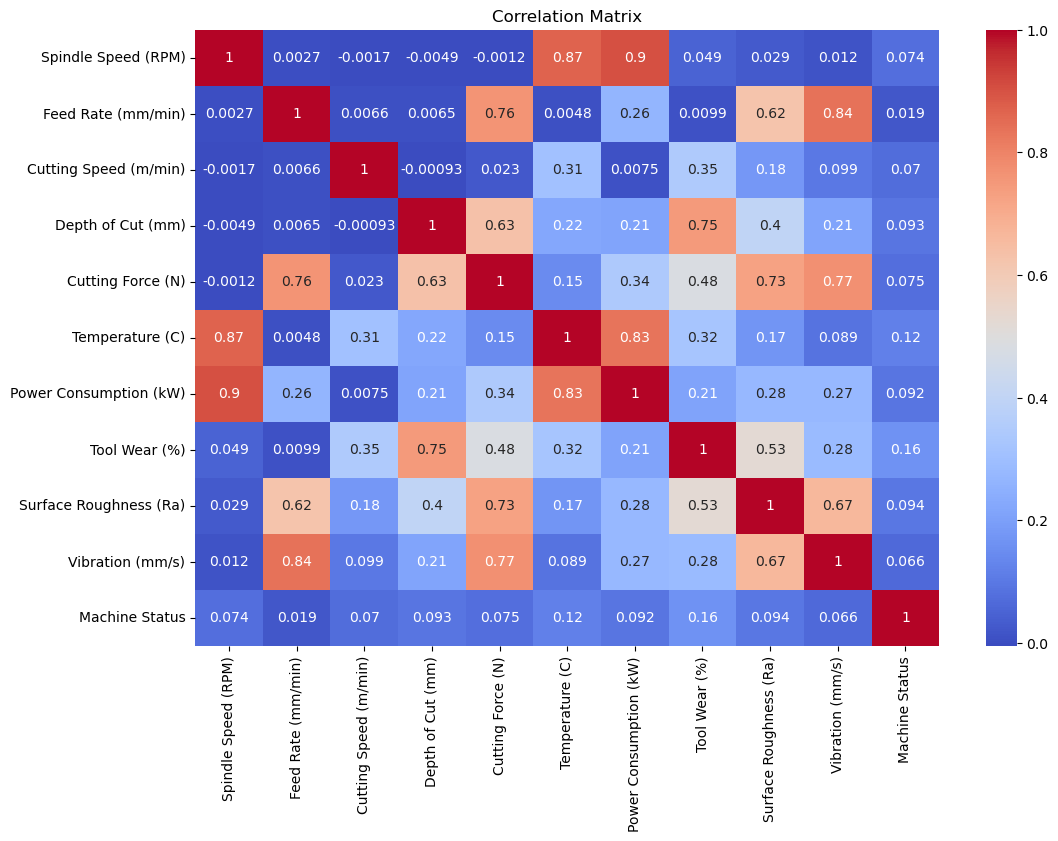

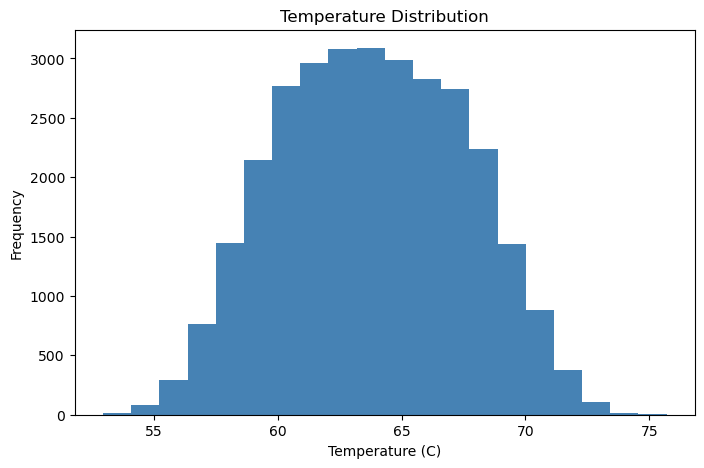

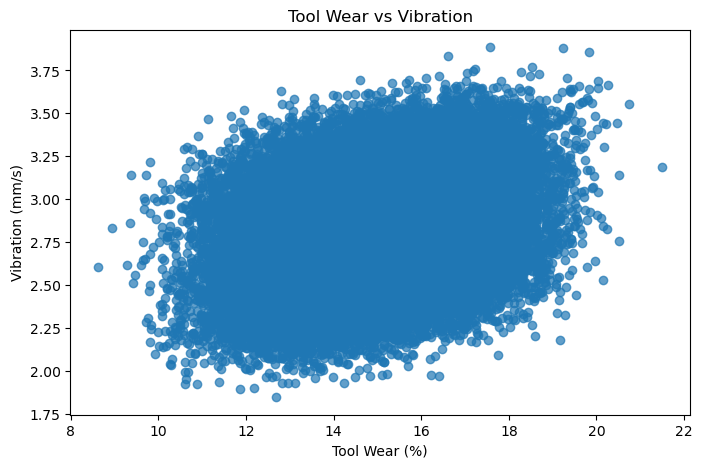


Random Forest Accuracy: 99.87 %

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7529
           1       1.00      0.72      0.84        36

    accuracy                           1.00      7565
   macro avg       1.00      0.86      0.92      7565
weighted avg       1.00      1.00      1.00      7565


Confusion Matrix:
 [[7529    0]
 [  10   26]]


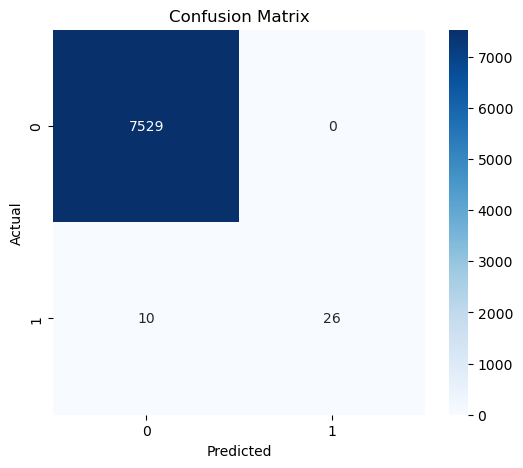


Feature Importance:

                   Feature  Importance
7            Tool Wear (%)    0.458353
5          Temperature (C)    0.139214
0      Spindle Speed (RPM)    0.069344
6   Power Consumption (kW)    0.065779
8   Surface Roughness (Ra)    0.041276
12        Power_Efficiency    0.038464
10                     MRR    0.036846
9         Vibration (mm/s)    0.032788
3        Depth of Cut (mm)    0.026810
1       Feed Rate (mm/min)    0.024501
4        Cutting Force (N)    0.023522
11               Tool_Load    0.022602
2    Cutting Speed (m/min)    0.020501


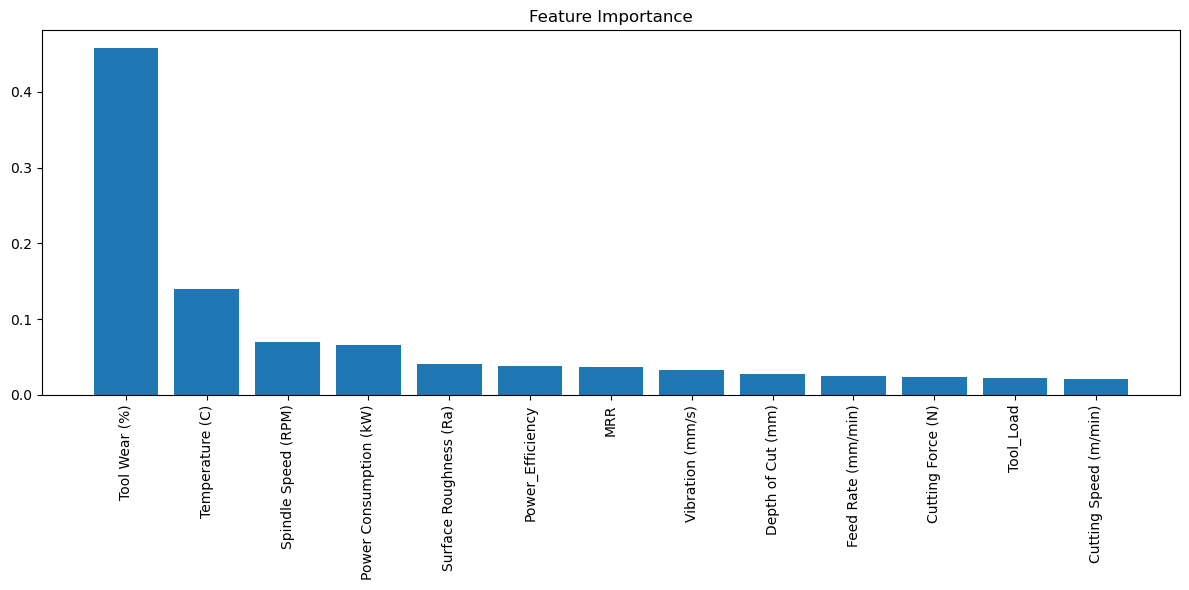


Classification prediction example:
Normal

Classification model saved successfully as CNC_Classification_Model.pkl
Decision Tree Accuracy = 0.9989
Random Forest Accuracy = 0.9987
Gradient Boosting Accuracy = 0.9978
SVM Accuracy = 0.9952
KNN Accuracy = 0.9952
Naive Bayes Accuracy = 0.9532
XGBoost Accuracy = 0.9991

Final model ranking:
XGBoost: 0.9991
Decision Tree: 0.9989
Random Forest: 0.9987
Gradient Boosting: 0.9978
SVM: 0.9952
KNN: 0.9952
Naive Bayes: 0.9532

Best classifier: XGBoost with accuracy 0.9991


In [1]:
# =========================================================
# Project 1: Classification - CNC Machine Status Prediction
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

# ---------------------------------------------------------
# 1. Load Data
# ---------------------------------------------------------
train_df = pd.read_excel(r"C:\Users\Kushal L\OneDrive\Desktop\KUSHALS FILES\major project\train.xlsx")
test_df = pd.read_excel(r"C:\Users\Kushal L\OneDrive\Desktop\KUSHALS FILES\major project\test.xlsx")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nSample training data:")
print(train_df.head())

# ---------------------------------------------------------
# 2. Clean Data
# ---------------------------------------------------------
train_df = train_df.drop_duplicates().dropna()
test_df = test_df.drop_duplicates().dropna()

print("\nCleaned Train shape:", train_df.shape)
print("Cleaned Test shape:", test_df.shape)

# ---------------------------------------------------------
# 3. Map Target Labels
# ---------------------------------------------------------
status_map = {
    "Normal": 0,
    "Healthy": 0,
    "Warning": 1,
    "Maintenance Required": 1,
    "Fault": 1
}

train_df["Machine Status"] = train_df["Machine Status"].map(status_map)
test_df["Machine Status"] = test_df["Machine Status"].map(status_map)

train_df = train_df.dropna(subset=["Machine Status"]).copy()
test_df = test_df.dropna(subset=["Machine Status"]).copy()

# ---------------------------------------------------------
# 4. Exploratory Data Analysis
# ---------------------------------------------------------
plt.figure(figsize=(12, 8))
sns.heatmap(train_df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(train_df["Temperature (C)"], bins=20, color="steelblue")
plt.title("Temperature Distribution")
plt.xlabel("Temperature (C)")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(train_df["Tool Wear (%)"], train_df["Vibration (mm/s)"], alpha=0.7)
plt.title("Tool Wear vs Vibration")
plt.xlabel("Tool Wear (%)")
plt.ylabel("Vibration (mm/s)")
plt.show()

# ---------------------------------------------------------
# 5. Feature Engineering
# ---------------------------------------------------------
train_df["MRR"] = (
    train_df["Feed Rate (mm/min)"]
    * train_df["Depth of Cut (mm)"]
    * train_df["Cutting Speed (m/min)"]
)

test_df["MRR"] = (
    test_df["Feed Rate (mm/min)"]
    * test_df["Depth of Cut (mm)"]
    * test_df["Cutting Speed (m/min)"]
)

train_df["Tool_Load"] = (
    train_df["Feed Rate (mm/min)"] * train_df["Depth of Cut (mm)"]
)
test_df["Tool_Load"] = (
    test_df["Feed Rate (mm/min)"] * test_df["Depth of Cut (mm)"]
)

train_df["Power_Efficiency"] = (
    train_df["MRR"] / train_df["Power Consumption (kW)"]
)
test_df["Power_Efficiency"] = (
    test_df["MRR"] / test_df["Power Consumption (kW)"]
)

# ---------------------------------------------------------
# 6. Select Features and Target
# ---------------------------------------------------------
features = [
    "Spindle Speed (RPM)",
    "Feed Rate (mm/min)",
    "Cutting Speed (m/min)",
    "Depth of Cut (mm)",
    "Cutting Force (N)",
    "Temperature (C)",
    "Power Consumption (kW)",
    "Tool Wear (%)",
    "Surface Roughness (Ra)",
    "Vibration (mm/s)",
    "MRR",
    "Tool_Load",
    "Power_Efficiency"
]

X_train = train_df[features]
y_train = train_df["Machine Status"]

X_test = test_df[features]
y_test = test_df["Machine Status"]

# ---------------------------------------------------------
# 7. Train Classification Model
# ---------------------------------------------------------
clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)
clf.fit(X_train, y_train)

# ---------------------------------------------------------
# 8. Evaluate Classification Model
# ---------------------------------------------------------
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print("\nRandom Forest Accuracy:", round(acc * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ---------------------------------------------------------
# 9. Feature Importance
# ---------------------------------------------------------
importance = clf.feature_importances_
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

print("\nFeature Importance:\n")
print(importance_df)

plt.figure(figsize=(12, 6))
plt.bar(importance_df["Feature"], importance_df["Importance"])
plt.xticks(rotation=90)
plt.title("Feature Importance")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 10. Predict New Machine Status
# ---------------------------------------------------------
def predict_machine_status(spindle_speed_rpm, feed_rate_mm_per_min, cutting_speed_m_per_min, depth_of_cut_mm):
    new_input = pd.DataFrame([{
        "Spindle Speed (RPM)": spindle_speed_rpm,
        "Feed Rate (mm/min)": feed_rate_mm_per_min,
        "Cutting Speed (m/min)": cutting_speed_m_per_min,
        "Depth of Cut (mm)": depth_of_cut_mm,
        "Cutting Force (N)": 380,
        "Temperature (C)": 45,
        "Power Consumption (kW)": 5.5,
        "Tool Wear (%)": 35,
        "Surface Roughness (Ra)": 1.2,
        "Vibration (mm/s)": 2.8,
        "MRR": feed_rate_mm_per_min * depth_of_cut_mm * cutting_speed_m_per_min,
        "Tool_Load": feed_rate_mm_per_min * depth_of_cut_mm,
        "Power_Efficiency": (feed_rate_mm_per_min * depth_of_cut_mm * cutting_speed_m_per_min) / 5.5
    }])

    prediction = clf.predict(new_input)[0]
    if prediction == 0:
        return "Normal"
    return "Warning / Maintenance Required"

print("\nClassification prediction example:")
status_result = predict_machine_status(
    spindle_speed_rpm=5000,
    feed_rate_mm_per_min=650,
    cutting_speed_m_per_min=170,
    depth_of_cut_mm=2.2
)
print(status_result)

# ---------------------------------------------------------
# 11. Save Classification Model
# ---------------------------------------------------------
joblib.dump(clf, "CNC_Classification_Model.pkl")
print("\nClassification model saved successfully as CNC_Classification_Model.pkl")

# ---------------------------------------------------------
# 12. Compare Multiple Classification Models
# ---------------------------------------------------------
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    results.append((name, acc))
    print(f"{name} Accuracy = {acc:.4f}")

print("\nFinal model ranking:")
for name, acc in sorted(results, key=lambda x: x[1], reverse=True):
    print(f"{name}: {acc:.4f}")

best_model_name, best_accuracy = max(results, key=lambda x: x[1])
print(f"\nBest classifier: {best_model_name} with accuracy {best_accuracy:.4f}")

# This is classification because Machine Status is a category.
# Use Accuracy, Precision, Recall, F1, and Confusion Matrix.
